# Análisis de los Juegos Olímpicos con Python y pandas
Python para Ciencia de Datos

**Autores:** Álvaro Tébar Folch y Pablo Sánchez-Migallón Quevedo



## Índice

0. [Carga y exploración de los datos](#seccion0)
1. [Reto 1. Relación entre las tablas](#reto1)
2. [Reto 2. Perfil de los atletas](#reto2)
3. [Reto 3. Medallas y rendimiento](#reto3)
4. [Reto 4. Participación de las mujeres](#reto4)

<a id='seccion0'></a>
# 0. Carga y exploración de los datos

Antes de resolver los retos exploramos las dos tablas de forma general: qué contiene cada fila, de qué tipo son las columnas, cuántos datos faltan y qué valores toman.

## 0.1 Carga de las tablas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", None)
COLOR_TEMP = {"Summer": "#eb6834", "Winter": "#2a78d6"}

df_atletas = pd.read_csv("atletas.csv")
df_medallas = pd.read_csv("medallas.csv")
print("Atletas :", df_atletas.shape)
print("Medallas:", df_medallas.shape)

Atletas : (135571, 8)
Medallas: (271116, 8)


In [2]:
df_atletas.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED


In [3]:
df_medallas.head()

,ID,Games,Year,Season,City,Sport,Event,Medal
0,1,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


Cada fila de atletas es una persona, con sus datos personales y su país. Cada fila de medallas es la participación de un atleta en una prueba concreta de unos Juegos, y la columna Medal indica si ganó medalla. Las dos tablas comparten la columna ID.

## 0.2 Tipos de datos y valores ausentes

In [4]:
df_atletas.info()

<class 'pandas.DataFrame'>
RangeIndex: 135571 entries, 0 to 135570
Data columns (total 8 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      135571 non-null  int64  
 1   Name    135571 non-null  str    
 2   Sex     135571 non-null  str    
 3   Age     129203 non-null  float64
 4   Height  101655 non-null  float64
 5   Weight  100686 non-null  float64
 6   Team    135571 non-null  str    
 7   NOC     135571 non-null  str    
dtypes: float64(3), int64(1), str(4)
memory usage: 8.3 MB


In [5]:
df_medallas.info()

<class 'pandas.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 8 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   ID      271116 non-null  int64
 1   Games   271116 non-null  str  
 2   Year    271116 non-null  int64
 3   Season  271116 non-null  str  
 4   City    271116 non-null  str  
 5   Sport   271116 non-null  str  
 6   Event   271116 non-null  str  
 7   Medal   39783 non-null   str  
dtypes: int64(2), str(6)
memory usage: 16.5 MB


Las columnas numéricas (edad, altura, peso y año) se leen como números y el resto como texto, así que no hace falta convertir nada. Los valores ausentes se concentran en cuatro columnas:

- **Age** falta en unos 6.400 atletas (4,7 %), y **Height** y **Weight** en una cuarta parte.
- **Medal** está vacía en 231.333 de las 271.116 filas (85 %). La tabla registra todas las participaciones, y el vacío significa que el atleta no ganó medalla. Por eso no se pueden eliminar esas filas.

## 0.3 Rango de las variables numéricas

In [6]:
df_atletas.describe().round(1)

,ID,Age,Height,Weight
count,135571.0,129203.0,101655.0,100686.0
mean,67786.0,24.4,176.3,72.0
std,39136.1,5.7,10.4,14.6
min,1.0,10.0,127.0,25.0
25%,33893.5,21.0,170.0,62.0
50%,67786.0,23.0,176.0,70.0
75%,101678.5,27.0,183.0,80.0
max,135571.0,97.0,226.0,214.0


El atleta medio tiene 24 años, mide 176 cm y pesa 72 kg. Los mínimos y los máximos son lo que hay que vigilar: hay un atleta de 97 años, algo poco creíble para un deportista, y pesos entre 25 y 214 kg que habrá que comprobar en el reto 2. Las alturas (127 a 226 cm) parecen razonables.

## 0.4 Variables categóricas

In [7]:
df_atletas.nunique()

ID        135571
Name      134732
Sex            2
Age           73
Height        95
Weight       220
Team        1013
NOC          230
dtype: int64

In [8]:
df_medallas.nunique()

ID        135571
Games         51
Year          35
Season         2
City          42
Sport         66
Event        765
Medal          3
dtype: int64

In [9]:
print(df_atletas["Sex"].value_counts(normalize=True).round(3), "\n")
print(df_medallas["Season"].value_counts(), "\n")
print(df_medallas["Medal"].value_counts(dropna=False))

Sex
M    0.749
F    0.251
Name: proportion, dtype: float64 

Season
Summer    222552
Winter     48564
Name: count, dtype: int64 

Medal
NaN       231333
Gold       13372
Bronze     13295
Silver     13116
Name: count, dtype: int64


**Nombres.** Hay 135.571 ID pero solo 134.732 nombres distintos. Como en esta tabla cada atleta aparece una sola vez, la diferencia no se debe a que un atleta tenga varias participaciones, sino a que hay atletas distintos que se llaman igual:

In [10]:
df_atletas[df_atletas["Name"].duplicated(keep=False)].sort_values("Name").head(6)

,ID,Name,Sex,Age,Height,Weight,Team,NOC
6324,6325,Abdul Aziz,M,21.0,NaN,NaN,Pakistan,PAK
6325,6326,Abdul Aziz,M,27.0,NaN,NaN,Pakistan,PAK
45251,45252,Abdul Hamid,M,21.0,175.0,68.0,Pakistan,PAK
45252,45253,Abdul Hamid,M,22.0,163.0,64.0,Pakistan,PAK
98968,98969,Abdul Rashid,M,24.0,NaN,NaN,Pakistan,PAK
98967,98968,Abdul Rashid,M,21.0,170.0,75.0,Pakistan,PAK


Son personas distintas con el mismo nombre y un ID diferente, como los dos jugadores pakistaníes llamados Abdul Aziz. Por eso, para identificar a un atleta usamos siempre el ID y nunca el nombre.

**País.** Dos columnas indican el país. NOC es el código de tres letras del Comité Olímpico Nacional por el que compite el atleta (USA, ESP, FRA...) y tiene 230 valores. Team es el nombre del equipo con el que compitió y tiene 1.013 valores, porque no siempre coincide con el país. Lo vemos con los atletas de Estados Unidos:

In [11]:
df_atletas.loc[df_atletas["NOC"] == "USA", "Team"].value_counts().head(6)

Team
United States       9051
United States-2      172
United States-1      134
United States-3       39
Vesper Boat Club      16
Angelita              14
Name: count, dtype: int64

Casi todos figuran como "United States". Cuando un país inscribió varios equipos en una misma prueba, se numeran ("United States-1", "United States-2"), y en las primeras ediciones algunos equipos aparecen con el nombre de su club o de su barco ("Vesper Boat Club", "Angelita"). Para analizar por país usamos NOC, que siempre indica el país.

**Ediciones.** Hay 35 años distintos pero 51 ediciones, porque hasta 1992 los Juegos de verano y los de invierno se celebraban el mismo año. El año no basta, por tanto, para identificar unos Juegos. La columna Games une el año y la temporada ("1992 Summer" y "1992 Winter" son dos ediciones distintas), y es la que usamos para identificar cada edición.

**Desequilibrios.** El 75 % de los atletas son hombres y el 82 % de las filas de la tabla de medallas son de verano. Hay que tenerlo en cuenta en todos los análisis por sexo y por temporada.

## 0.5 Duplicados y relación entre las tablas

In [12]:
print("Filas duplicadas en atletas :", df_atletas.duplicated().sum())
print("Filas duplicadas en medallas:", df_medallas.duplicated().sum())
print("¿Cada ID aparece una sola vez en atletas?", df_atletas["ID"].is_unique)
print("IDs de medallas que no existen en atletas:", (~df_medallas["ID"].isin(df_atletas["ID"])).sum())
print("Máximo de filas de un mismo atleta en medallas:", df_medallas["ID"].value_counts().max())

Filas duplicadas en atletas : 0
Filas duplicadas en medallas: 1398
¿Cada ID aparece una sola vez en atletas? True
IDs de medallas que no existen en atletas: 0
Máximo de filas de un mismo atleta en medallas: 58


Hay 1.398 filas repetidas en la tabla de medallas, es decir, filas con el mismo atleta, la misma edición, la misma prueba y el mismo resultado. Antes de decidir qué hacer con ellas miramos de qué deportes son y cómo son:

In [13]:
print(df_medallas[df_medallas.duplicated()]["Sport"].value_counts(), "\n")
repetidas = df_medallas[df_medallas.duplicated(keep=False) & (df_medallas["Sport"] != "Art Competitions")]
repetidas.sort_values("ID").head(4)

Sport
Art Competitions    1315
Sailing               48
Cycling               32
Equestrianism          3
Name: count, dtype: int64 



,ID,Games,Year,Season,City,Sport,Event,Medal
10866,5935,1908 Summer,1908,Summer,London,Cycling,Cycling Men's Sprint,NaN
10867,5935,1908 Summer,1908,Summer,London,Cycling,Cycling Men's Sprint,NaN
12638,6883,1908 Summer,1908,Summer,London,Cycling,Cycling Men's Sprint,NaN
12639,6883,1908 Summer,1908,Summer,London,Cycling,Cycling Men's Sprint,NaN


El 94 % de las filas repetidas (1.315) son de Art Competitions, y el resto, de unas pocas pruebas de ciclismo, vela e hípica de principios del siglo XX. Son copias exactas: en el ejemplo, dos ciclistas aparecen dos veces cada uno en el sprint de 1908 con el mismo resultado. En el resto de la tabla casi siempre hay una sola fila por atleta y prueba (las pocas excepciones son pruebas de vela y remo de 1900 que se disputaron en dos carreras, con resultados distintos). Si dejáramos las copias, esas pruebas contarían dos veces para el mismo atleta, y si la fila tiene medalla, esa medalla contaría doble. Por eso las eliminaremos en la limpieza.

En cuanto a la relación entre tablas, cada ID aparece una sola vez en atletas y todos los ID de medallas tienen su atleta en la tabla de atletas. Al unir las dos tablas por ID, por tanto, ninguna participación se queda sin los datos de su atleta. Un atleta tiene una fila en atletas y tantas filas en medallas como pruebas disputó, hasta 58 en el caso más extremo.

## 0.6 A qué momento corresponde la edad

La tabla de atletas tiene una sola edad por persona, pero muchos atletas compitieron en varios Juegos con edades distintas. En el reto 2 necesitamos la edad que tenía cada atleta en cada edición, así que primero hay que averiguar a qué año corresponde la edad de la tabla.

In [14]:
# Atletas conocidos: edad de la tabla frente a su edad real en el primer y el último año en que compitieron
# (edades reales calculadas con su fecha de nacimiento y la fecha de cada edición)
edad_real = pd.DataFrame({
    "ID": [94406, 132627, 11951, 13029],
    "edad real en el primer año": [15, 20, 20, 17],
    "edad real en el último año": [31, 27, 40, 29],
})
comprobacion = (edad_real
    .merge(df_atletas[["ID", "Name", "Age"]], on="ID")
    .merge(df_medallas.groupby("ID")["Year"].agg(["min", "max"]).reset_index(), on="ID")
    .rename(columns={"Name": "atleta", "Age": "edad en la tabla", "min": "primer año", "max": "último año"}))
comprobacion[["atleta", "edad en la tabla", "primer año", "edad real en el primer año", "último año", "edad real en el último año"]]

,atleta,edad en la tabla,primer año,edad real en el primer año,último año,edad real en el último año
0,"Michael Fred Phelps, II",15.0,2000,15,2016,31
1,Yao Ming,20.0,2000,20,2008,27
2,Ole Einar Bjrndalen,20.0,1994,20,2014,40
3,Usain St. Leo Bolt,17.0,2004,17,2016,29


En los cuatro casos la edad de la tabla coincide exactamente con la que tenía el atleta en su primera participación, y no con la de la última: Phelps aparece con 15 años, los que tenía en Sídney 2000, y no con los 31 de Río 2016. La edad de la tabla es, por tanto, **la de la primera participación**.

Para obtener la edad en cada edición le sumamos los años transcurridos desde el debut:

edad en la edición = edad en el debut + (año de la edición − año del debut)

Phelps tenía 15 años en 2000, así que en Río 2016 tenía 15 + 16 = 31, que es su edad real en esos Juegos. El resultado puede desviarse un año según la fecha de cumpleaños de cada atleta, pero es mucho más preciso que usar la edad del debut en todas sus participaciones.

## 0.7 Atletas de más de 75 años

In [15]:
mayores = df_atletas.loc[df_atletas["Age"] > 75, "ID"]
print("Atletas de más de 75 años:", len(mayores))
print("Deportes en los que compitieron:", df_medallas.loc[df_medallas["ID"].isin(mayores), "Sport"].unique())

# Tipos de prueba de Art Competitions
pruebas_arte = df_medallas.loc[df_medallas["Sport"] == "Art Competitions", "Event"]
print("Pruebas de Art Competitions:", pruebas_arte.str.split(",").str[0].unique())

Atletas de más de 75 años: 8
Deportes en los que compitieron: <StringArray>
['Art Competitions']
Length: 1, dtype: str
Pruebas de Art Competitions: ['Art Competitions Mixed Sculpturing'
 'Art Competitions Mixed Architecture' 'Art Competitions Mixed Painting'
 'Art Competitions Mixed Literature' 'Art Competitions Mixed Music'
 'Art Competitions Mixed Unknown Event']


Los ocho compitieron en Art Competitions. Como muestran los nombres de sus pruebas, eran concursos de arquitectura, literatura, música, pintura y escultura: entre 1912 y 1948 los Juegos dieron medallas a obras de arte inspiradas en el deporte. No son competiciones deportivas, el COI dejó de contar esas medallas en su medallero oficial, y sus participantes distorsionan los análisis de edad y físico (todos los mayores de 75 años salen de aquí). Por eso las excluimos.

## 0.8 Limpieza y tabla combinada

Con lo anterior, la limpieza consiste en:

- eliminar las filas duplicadas y las de Art Competitions, y quitar de atletas a quienes solo participaron en arte;
- calcular la edad en cada edición como edad del debut + (año de la edición − año de debut). El año de debut se calcula antes de filtrar, porque es el año al que corresponde la edad;
- unir las dos tablas por ID en una tabla combinada (df), porque casi todos los análisis necesitan datos de ambas;
- crear la tabla participaciones, con una fila por atleta y edición, que es la unidad para contar participaciones y edades sin que un atleta con muchas pruebas pese más.

In [16]:
anio_debut = df_medallas.groupby("ID")["Year"].min().rename("anio_debut")

df_medallas = df_medallas.drop_duplicates()
df_medallas = df_medallas[df_medallas["Sport"] != "Art Competitions"].reset_index(drop=True)
df_atletas = df_atletas[df_atletas["ID"].isin(df_medallas["ID"])].reset_index(drop=True)

df = df_medallas.merge(df_atletas, on="ID").merge(anio_debut, on="ID")
df["edad_juego"] = df["Age"] + (df["Year"] - df["anio_debut"])
df["medalla"] = df["Medal"].notna()

participaciones = df.drop_duplicates(["ID", "Games"])

print("Atletas:", df_atletas.shape, "| Medallas:", df_medallas.shape)
print("Tabla combinada:", df.shape, "| Participaciones (atleta y edición):", len(participaciones))

Atletas: (133781, 8) | Medallas: (267455, 8)
Tabla combinada: (267455, 18) | Participaciones (atleta y edición): 185410


<a id='reto1'></a>
# Reto 1. Relación entre las tablas

## A) Tareas de análisis

### 1.1 Qué aporta cada tabla

**Enunciado.** Explica brevemente (en 5–8 líneas) qué aporta cada tabla (atletas y medallas) y cómo se relacionan entre sí.

La tabla de atletas describe a las personas: una fila por atleta con su nombre, sexo, edad en su primera participación, altura, peso y país. La tabla de medallas describe las competiciones: una fila por atleta y prueba disputada, con la edición, el año, la temporada, la ciudad, el deporte, la prueba y la medalla, que queda vacía si no hubo podio. Se relacionan por ID en una relación de uno a muchos, como vimos en 0.5: cada atleta aparece una vez en la primera y tantas veces como pruebas disputó en la segunda. Como el país y el físico solo están en atletas, y la fecha y el resultado solo en medallas, la mayoría de los análisis necesitan unir las dos tablas.

### 1.2 Listado de atletas de ejemplo

**Enunciado.** Muestra un listado de ejemplo (5–10 filas) con: nombre del atleta, país, tipo de juegos, años en los que participó y medallas obtenidas en cada año.

Elegimos a los 8 atletas con más medallas, porque son los que tienen más información que mostrar en cada año. Si un atleta hubiera competido en verano y en invierno, aparecería en dos filas, una por tipo de juegos.

In [17]:
top_ids = df.loc[df["medalla"], "ID"].value_counts().head(8).index

def medallas_del_anio(g):
    cuenta = g["Medal"].value_counts()
    return ", ".join(f"{cuenta[m]} {m}" for m in ["Gold", "Silver", "Bronze"] if m in cuenta) or "sin medalla"

filas = []
for id_ in top_ids:
    for temporada, g in df[df["ID"] == id_].groupby("Season"):
        filas.append({
            "atleta": g["Name"].iloc[0],
            "país": g["NOC"].iloc[0],
            "juegos": temporada,
            "años": ", ".join(str(a) for a in sorted(g["Year"].unique())),
            "medallas por año": " | ".join(f"{a}: {medallas_del_anio(ga)}" for a, ga in g.groupby("Year")),
        })
pd.DataFrame(filas)

,atleta,país,juegos,años,medallas por año
0,"Michael Fred Phelps, II",USA,Summer,"2000, 2004, 2008, 2012, 2016","2000: sin medalla | 2004: 6 Gold, 2 Bronze | 2008: 8 Gold | 2012: 4 Gold, 2 Silver | 2016: 5 Gold, 1 Silver"
1,Larysa Semenivna Latynina (Diriy-),URS,Summer,"1956, 1960, 1964","1956: 4 Gold, 1 Silver, 1 Bronze | 1960: 3 Gold, 2 Silver, 1 Bronze | 1964: 2 Gold, 2 Silver, 2 Bronze"
2,Nikolay Yefimovich Andrianov,URS,Summer,"1972, 1976, 1980","1972: 1 Gold, 1 Silver, 1 Bronze | 1976: 4 Gold, 2 Silver, 1 Bronze | 1980: 2 Gold, 2 Silver, 1 Bronze"
3,Ole Einar Bjrndalen,NOR,Winter,"1994, 1998, 2002, 2006, 2010, 2014","1994: sin medalla | 1998: 1 Gold, 1 Silver | 2002: 4 Gold | 2006: 2 Silver, 1 Bronze | 2010: 1 Gold, 1 Silver | 2014: 2 Gold"
4,Edoardo Mangiarotti,ITA,Summer,"1936, 1948, 1952, 1956, 1960","1936: 1 Gold | 1948: 2 Silver, 1 Bronze | 1952: 2 Gold, 2 Silver | 1956: 2 Gold, 1 Bronze | 1960: 1 Gold, 1 Silver"
5,Takashi Ono,JPN,Summer,"1952, 1956, 1960, 1964","1952: 1 Bronze | 1956: 1 Gold, 3 Silver, 1 Bronze | 1960: 3 Gold, 1 Silver, 2 Bronze | 1964: 1 Gold"
6,Borys Anfiyanovych Shakhlin,URS,Summer,"1956, 1960, 1964","1956: 2 Gold | 1960: 4 Gold, 2 Silver, 1 Bronze | 1964: 1 Gold, 2 Silver, 1 Bronze"
7,Natalie Anne Coughlin (-Hall),USA,Summer,"2004, 2008, 2012","2004: 2 Gold, 2 Silver, 1 Bronze | 2008: 1 Gold, 2 Silver, 3 Bronze | 2012: 1 Bronze"


El listado deja ver dos cosas que importan para el resto del trabajo. Un mismo atleta puede ganar varias medallas en una edición (Phelps ganó 8 oros en 2008), y la mayoría de estos atletas compitieron en tres o más Juegos seguidos.

### 1.3 Preguntas que necesitan las dos tablas

**Enunciado.** Indica 3 preguntas que no se podrían responder usando solo una de las tablas.

1. **¿Qué países han ganado más medallas en los Juegos de Invierno?** El país solo está en atletas; la temporada y la medalla, solo en medallas.
2. **¿Los jugadores de baloncesto que ganan medalla son más altos que los que no?** La altura está en atletas; el deporte y el resultado, en medallas.
3. **¿Ha cambiado la edad media de las mujeres olímpicas a lo largo del siglo XX?** El sexo y la edad están en atletas; el año, en medallas.

### 1.4 Participaciones por país

**Enunciado.** Haz un gráfico de barras apiladas con el nº de participaciones por país para los 10 países con más participaciones, separando Verano/Invierno. Justifica por qué barras apiladas es una buena elección (o propón otro tipo de gráfica y justifícala).

Entendemos por participación la presencia de un atleta en unos Juegos, igual que la función resumen_participacion del enunciado, en la que Phelps tiene 5 participaciones, una por cada Juegos. Por eso no contamos filas de la tabla de medallas, porque cada fila es una prueba: Phelps tiene 8 filas en 2008 porque disputó 8 pruebas, pero es una sola participación. Usamos la tabla participaciones, que tiene una fila por atleta y edición.

In [18]:
part_pais = participaciones.groupby(["NOC", "Season"]).size().unstack(fill_value=0)
part_pais = part_pais.rename(columns={"Summer": "Verano", "Winter": "Invierno"})
part_pais["Total"] = part_pais["Verano"] + part_pais["Invierno"]
part_pais["% verano"] = (100 * part_pais["Verano"] / part_pais["Total"]).round(1)
part_pais["% invierno"] = (100 * part_pais["Invierno"] / part_pais["Total"]).round(1)

top10 = part_pais.sort_values("Total", ascending=False).head(10).reset_index(names="País")
top10.columns.name = None
top10.index = range(1, 11)
top10

,País,Verano,Invierno,Total,% verano,% invierno
1,USA,10030,2488,12518,80.1,19.9
2,GBR,7471,857,8328,89.7,10.3
3,FRA,6831,1246,8077,84.6,15.4
4,ITA,5587,1485,7072,79.0,21.0
5,CAN,4596,1821,6417,71.6,28.4
6,GER,4954,1302,6256,79.2,20.8
7,AUS,5105,342,5447,93.7,6.3
8,SWE,3973,1387,5360,74.1,25.9
9,JPN,4158,1194,5352,77.7,22.3
10,URS,3596,764,4360,82.5,17.5


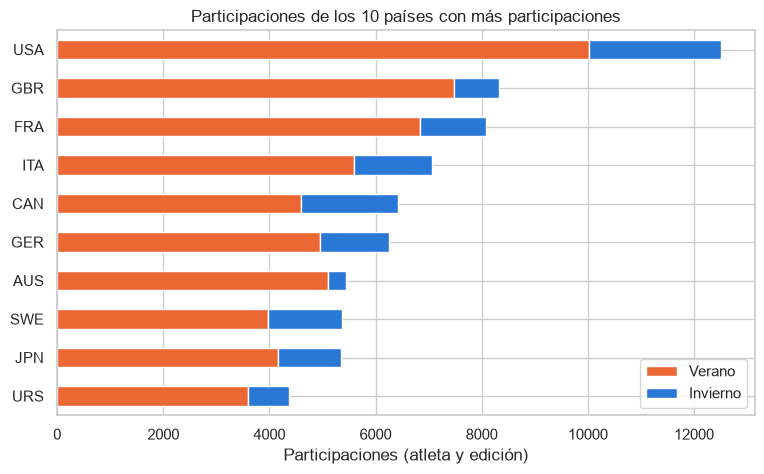

In [19]:
ax = top10.set_index("País")[["Verano", "Invierno"]].iloc[::-1].plot(
    kind="barh", stacked=True, figsize=(9, 5), color=[COLOR_TEMP["Summer"], COLOR_TEMP["Winter"]])
ax.set_title("Participaciones de los 10 países con más participaciones")
ax.set_xlabel("Participaciones (atleta y edición)")
ax.set_ylabel("")
plt.show()

**Por qué barras apiladas.** La tarea pide dos cosas a la vez, el total de cada país y su reparto entre verano e invierno, y la barra apilada muestra ambas: la longitud es el total y los tramos son el reparto.

**Qué se ve.** Estados Unidos tiene muchas más participaciones que ningún otro país (12.518, un 50 % más que Gran Bretaña). En los diez países la mayoría de las participaciones son de verano, que es la temporada con más deportes y más ediciones. La parte de invierno depende de cada país: en Canadá (28 %) y Suecia (26 %) supera la cuarta parte, mientras que en Australia es solo del 6 %, algo coherente con la tradición de deportes de nieve y hielo de cada país.

## B) Función de resumen de participaciones

**Qué hace.** resumen_participacion(id_atleta, df_medallas) devuelve el número de Juegos en los que participó un atleta y sus años agrupados en intervalos consecutivos.

**Apuntes.**
- Dos Juegos son consecutivos si son de la misma temporada y entre ellos no se celebraron otros Juegos de esa temporada. Casi siempre equivale a 4 años, el salto que menciona el enunciado, pero no siempre. Los Juegos de invierno de 1992 y 1994 están separados por 2 años y son seguidos. Entre 1936 y 1948 no hubo Juegos por la Segunda Guerra Mundial, así que un atleta que compitió en ambos no se saltó ninguna edición. Para saber qué Juegos se celebraron, la función usa los años que aparecen en los datos.
- Las participaciones se cuentan como Juegos distintos (año y temporada), no como filas. Las varias pruebas de un atleta en unos mismos Juegos y las posibles filas repetidas cuentan una sola vez.
- Los años se ordenan antes de formar los intervalos, y cada intervalo se alarga mientras los Juegos sean consecutivos.
- Si un atleta compitió en verano y en invierno, los intervalos de cada temporada se calculan por separado, porque un año de verano y uno de invierno no forman una secuencia.

In [20]:
def resumen_participacion(id_atleta, df_medallas):
    juegos = df_medallas[df_medallas["ID"] == id_atleta][["Year", "Season"]].drop_duplicates()
    intervalos = []
    for temporada, g in juegos.groupby("Season"):
        calendario = sorted(df_medallas[df_medallas["Season"] == temporada]["Year"].unique())
        posiciones = sorted(calendario.index(a) for a in g["Year"])
        inicio = posiciones[0]
        for i in range(1, len(posiciones) + 1):
            # Se cierra el intervalo al llegar al final o si se salta alguna edición
            if i == len(posiciones) or posiciones[i] != posiciones[i - 1] + 1:
                intervalos.append(f"{calendario[inicio]}-{calendario[posiciones[i - 1]]}")
                if i < len(posiciones):
                    inicio = posiciones[i]
    return {"participaciones": len(juegos), "intervalos": sorted(intervalos)}

**Casos de prueba.** El caso de Phelps del enunciado, el ejemplo del enunciado con un hueco en 2004, un atleta de invierno que pasa de 1992 a 1994 (los dos con atletas ficticios añadidos a los datos reales) y un ID que no existe.

In [21]:
assert resumen_participacion(94406, df_medallas) == {"participaciones": 5, "intervalos": ["2000-2016"]}

ficticio = pd.DataFrame({"ID": -1, "Year": [1992, 1996, 2000, 2008, 2012, 2016], "Season": "Summer"})
assert resumen_participacion(-1, pd.concat([df_medallas, ficticio])) == \
    {"participaciones": 6, "intervalos": ["1992-2000", "2008-2016"]}

ficticio_invierno = pd.DataFrame({"ID": -2, "Year": [1988, 1992, 1994, 1998], "Season": "Winter"})
assert resumen_participacion(-2, pd.concat([df_medallas, ficticio_invierno]))["intervalos"] == ["1988-1998"]

assert resumen_participacion(-99, df_medallas) == {"participaciones": 0, "intervalos": []}
print("Pruebas superadas")
resumen_participacion(id_atleta=94406, df_medallas=df_medallas)

Pruebas superadas


{'participaciones': 5, 'intervalos': ['2000-2016']}

<a id='reto2'></a>
# Reto 2. Perfil de los atletas

## A) Tareas de análisis

### 2.1 Edad media en verano e invierno

**Enunciado.** Obtén la edad media de los atletas diferenciando entre juegos de Verano e Invierno (muestra ambas y compáralas en 3–5 líneas).

Usamos la edad en cada edición y contamos una vez a cada atleta por edición. Así un atleta que fue a cuatro Juegos aporta sus cuatro edades reales y no cuatro veces la de su debut.

In [22]:
participaciones.groupby("Season")["edad_juego"].agg(["mean", "median", "std"]).round(2)

,mean,median,std
Season,,,
Summer,25.7,25.0,5.84
Winter,25.1,25.0,4.96


La edad media es casi la misma: 25,7 años en verano y 25,1 en invierno, con la misma mediana de 25. La diferencia está en la dispersión, mayor en verano (desviación de 5,8 frente a 5,0), porque los Juegos de verano reúnen deportes con perfiles muy distintos, desde gimnastas adolescentes hasta tiradores o jinetes veteranos. La temporada influye poco en la edad; el deporte, mucho más.

### 2.2 Edades de los cinco países con más atletas

**Enunciado.** Muestra un histograma de edades de los 5 países con más atletas participantes (un FacetGrid de histogramas por país).

Los países se ordenan por atletas distintos. Cada histograma está en porcentaje dentro de su país, porque lo que interesa es comparar la forma de las distribuciones y, con conteos, Estados Unidos taparía al resto.

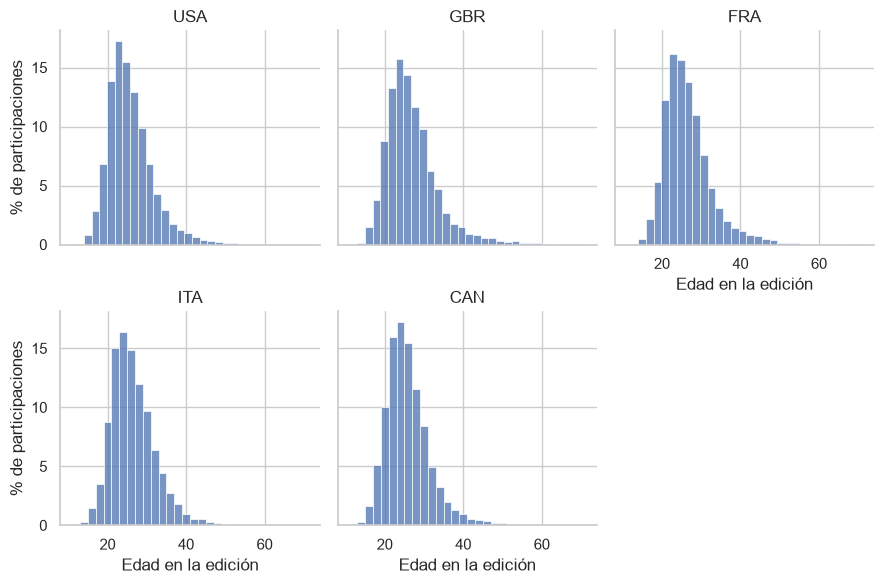

In [23]:
top5_paises = df_atletas["NOC"].value_counts().head(5).index
datos = participaciones[participaciones["NOC"].isin(top5_paises)]

g = sns.FacetGrid(datos, col="NOC", col_order=top5_paises, col_wrap=3, height=3)
g.map(sns.histplot, "edad_juego", binwidth=2, stat="percent")
g.set_axis_labels("Edad en la edición", "% de participaciones")
g.set_titles("{col_name}")
plt.show()

Las cinco distribuciones se parecen mucho. Para ver en qué se diferencian, calculamos la mediana, el peso de los atletas de 35 años o más y qué parte de las participaciones de cada país es anterior a 1950.

In [24]:
resumen_edades = datos.groupby("NOC").agg(
    atletas=("ID", "nunique"),
    mediana=("edad_juego", "median"),
    mayores_35=("edad_juego", lambda s: round(100 * (s >= 35).mean(), 1)),
    antes_1950=("Year", lambda s: round(100 * (s < 1950).mean(), 1)),
).loc[top5_paises]
resumen_edades.columns = ["atletas", "mediana de edad", "% con 35 años o más", "% antes de 1950"]
resumen_edades.rename_axis(None)

,atletas,mediana de edad,% con 35 años o más,% antes de 1950
USA,9354,25.0,7.1,23.1
GBR,6124,25.0,9.4,31.5
FRA,5973,25.0,8.0,33.0
ITA,4797,25.0,6.9,19.4
CAN,4767,24.0,6.2,12.5


In [25]:
antes = participaciones["Year"] < 1950
print("Edad media antes de 1950:", round(participaciones.loc[antes, "edad_juego"].mean(), 1))
print("Edad media desde 1950   :", round(participaciones.loc[~antes, "edad_juego"].mean(), 1))

Edad media antes de 1950: 26.6
Edad media desde 1950   : 25.5


Todos los países tienen el pico entre los 20 y los 26 años y una cola hacia edades altas. Las diferencias están en esa cola. Gran Bretaña (9,4 %) y Francia (8,0 %) tienen más participaciones de atletas de 35 años o más que Canadá (6,2 %), el único con mediana de 24. La explicación está en la historia de cada país: británicos y franceses tienen un tercio de sus participaciones antes de 1950, cuando la edad media era más alta (26,6 años frente a 25,5), y Canadá solo un 12,5 %.

### 2.3 Reparto por sexo y temporada

**Enunciado.** Muestra la distribución porcentual segregando por Hombre/Mujer y Verano/Invierno, en una gráfica adecuada (en porcentajes, no conteos). Justifica el tipo de gráfica por el que has optado.

Contamos a cada persona una vez por temporada y calculamos el porcentaje de hombres y mujeres dentro de cada temporada.

In [26]:
atletas_temporada = df.drop_duplicates(["ID", "Season"])
reparto = pd.crosstab(atletas_temporada["Season"], atletas_temporada["Sex"], normalize="index") * 100
reparto = reparto.rename(index={"Summer": "Verano", "Winter": "Invierno"}, columns={"F": "Mujer", "M": "Hombre"})
reparto = reparto.rename_axis(index=None, columns=None)
reparto.round(1)

,Mujer,Hombre
Verano,24.9,75.1
Invierno,27.2,72.8


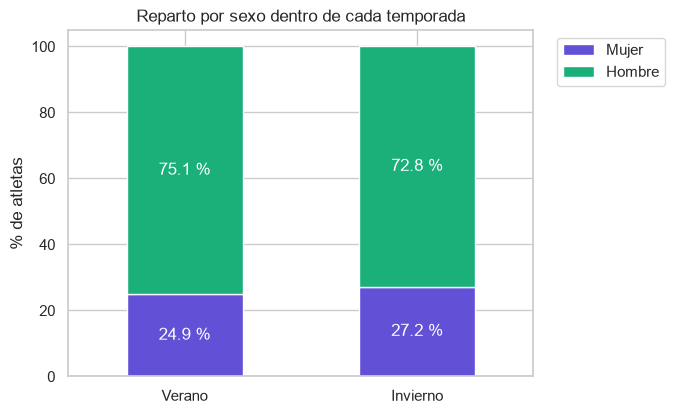

In [27]:
ax = reparto.plot(kind="bar", stacked=True, figsize=(6, 4.5), color=["#6250d6", "#1baf7a"], rot=0)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f %%", label_type="center", color="white")
ax.set_title("Reparto por sexo dentro de cada temporada")
ax.set_ylabel("% de atletas")
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1))
plt.show()

**Por qué barras apiladas al 100 %.** Cada barra es una temporada completa (el 100 % de sus atletas) dividida en hombres y mujeres. Así se ve directamente qué parte de los atletas es de cada sexo, y las dos temporadas se comparan en la misma escala.

**Qué se ve.** En las dos temporadas hay unas tres veces más hombres que mujeres. Las mujeres son el 24,9 % de los atletas de verano y el 27,2 % de los de invierno. Es un dato acumulado de 120 años; en el reto 4 vemos cómo ha cambiado con el tiempo.

### 2.4 Físico de las mujeres en los deportes con más mujeres

**Enunciado.** Calcula la altura y peso medio de las mujeres en los 5 deportes en los que haya más mujeres que hombres, y muestra una visualización que permita comparar esa distribución (p. ej., boxplots por deporte). Añade al menos 2 comentarios sobre qué muestran los resultados obtenidos.

Primero buscamos los deportes con más mujeres que hombres, contando a cada persona una vez por deporte.

In [28]:
atletas_deporte = df.drop_duplicates(["ID", "Sport"])
sexo_deporte = pd.crosstab(atletas_deporte["Sport"], atletas_deporte["Sex"])
sexo_deporte = sexo_deporte.rename(columns={"F": "Mujeres", "M": "Hombres"}).rename_axis(index=None, columns=None)
sexo_deporte["% mujeres"] = (100 * sexo_deporte["Mujeres"] / (sexo_deporte["Mujeres"] + sexo_deporte["Hombres"])).round(1)
mas_mujeres = sexo_deporte[sexo_deporte["Mujeres"] > sexo_deporte["Hombres"]].sort_values("% mujeres", ascending=False)
mas_mujeres

,Mujeres,Hombres,% mujeres
Rhythmic Gymnastics,567,0,100.0
Softball,367,0,100.0
Synchronized Swimming,550,0,100.0
Figure Skating,824,748,52.4
Badminton,412,399,50.8
Table Tennis,377,372,50.3


Salen seis deportes. Los tres primeros no tienen ningún hombre, y es lo esperable: en el programa olímpico son exclusivamente femeninos. La gimnasia rítmica y la natación sincronizada solo tienen pruebas de mujeres, y el softball es la versión femenina del béisbol, que en los Juegos jugaban los hombres. Los otros tres están casi empatados. Nos quedamos con los cinco de mayor porcentaje de mujeres, lo que deja fuera el tenis de mesa (50,3 %).

In [29]:
deportes5 = mas_mujeres.head(5).index
mujeres = atletas_deporte[atletas_deporte["Sport"].isin(deportes5) & (atletas_deporte["Sex"] == "F")]

medias = mujeres.groupby("Sport").agg(
    altura=("Height", "mean"),
    peso=("Weight", "mean"),
    sin_altura=("Height", lambda s: 100 * s.isna().mean()),
).round(1).sort_values("altura")
medias.columns = ["altura media (cm)", "peso medio (kg)", "% sin altura"]
medias.rename_axis(None)

,altura media (cm),peso medio (kg),% sin altura
Figure Skating,160.5,49.9,33.9
Rhythmic Gymnastics,167.6,48.5,4.6
Badminton,168.1,61.1,10.9
Synchronized Swimming,168.1,55.7,5.5
Softball,169.0,66.9,8.2


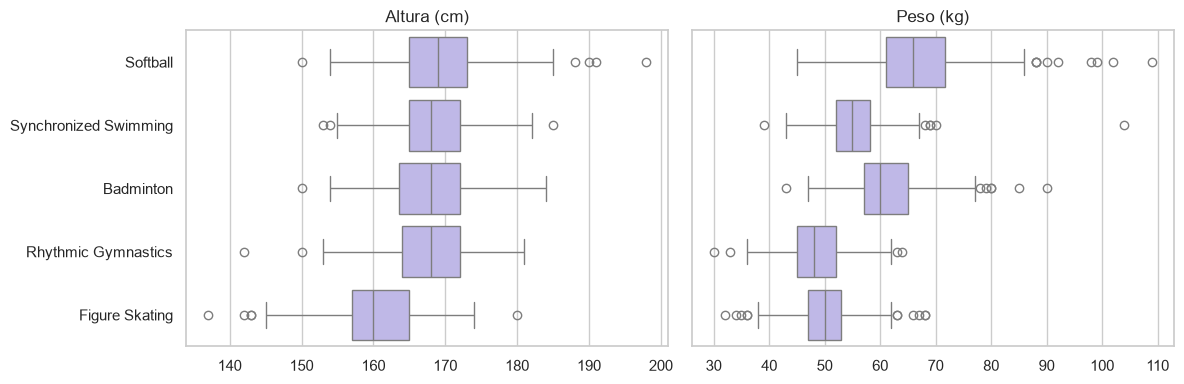

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=mujeres, x="Height", y="Sport", ax=axes[0], color="#b9b0ef")
sns.boxplot(data=mujeres, x="Weight", y="Sport", ax=axes[1], color="#b9b0ef")
axes[0].set(title="Altura (cm)", xlabel="", ylabel="")
axes[1].set(title="Peso (kg)", xlabel="", ylabel="")
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

**Comentarios.**

1. **El peso diferencia estos deportes mucho más que la altura.** Cuatro de los cinco tienen alturas medias entre 167,6 y 169 cm, pero una gimnasta rítmica pesa de media 48,5 kg y una jugadora de softball 66,9 kg. Con la misma estatura, el peso refleja lo que pide cada deporte: ligereza y flexibilidad en la gimnasia, potencia para batear y lanzar en el softball. Las cajas de peso más estrechas son las del patinaje, la natación sincronizada y la gimnasia rítmica, señal de una selección física muy uniforme, mientras que el softball tiene más dispersión porque cada posición del equipo pide un físico distinto.

2. **Las patinadoras son más bajas que el resto.** Miden de media 160,5 cm, unos siete centímetros menos que las deportistas de los otros cuatro deportes. Una explicación posible está en el propio deporte. En el patinaje artístico se hacen saltos con varios giros en el aire, que son más fáciles con un cuerpo pequeño y ligero, y en la modalidad por parejas el patinador levanta y lanza a su compañera. Hay que tomar esta media con cautela, porque falta la altura del 33,9 % de las patinadoras (columna % sin altura de la tabla anterior), muchas más que en los otros cuatro deportes.

## B) Función de atletas extremos

**Qué hace.** extremos_atletas(df_atletas) devuelve el atleta más joven, el más mayor, el más alto, el más bajo, el más ligero y el más pesado, con la estructura de diccionario del enunciado.

**Valores no plausibles.** El enunciado pide descartar las edades, alturas y pesos nulos o no plausibles, y justificar los umbrales usados. Estos son los nuestros:

| Variable | Mín | Máx | Motivo |
|---|---|---|---|
| Edad | 10 | 75 | En 0.7 vimos que todos los mayores de 75 eran participantes de Art Competitions, no deportistas. El mínimo de 10 deja dentro al atleta más joven de los datos (10 años, gimnasia en 1896), que es real |
| Altura (cm) | 120 | 230 | Por debajo de 120 cm se trataría de un niño o de un error de unidades. El máximo de los datos es 226 cm, así que 230 solo descarta errores |
| Peso (kg) | 25 | 230 | Deja dentro a las gimnastas más ligeras y a los pesos pesados de judo, que superan los 200 kg (en halterofilia el máximo es 176,5 kg) |

**Empates.** Puede haber varios atletas con el mismo valor extremo, por ejemplo dos atletas con la altura mínima. El enunciado pide desempatar primero por número de participaciones olímpicas y, si siguen empatados, por orden alfabético del nombre. Las participaciones están en la tabla de medallas y se cuentan con resumen_participacion, pero la función del enunciado solo recibe df_atletas. Por eso le añadimos df_medallas como segundo parámetro, que por defecto es la tabla de medallas ya limpia. Así la función se puede llamar como en el enunciado, extremos_atletas(df_atletas), y desempata por participaciones. Si se pasa None, desempata directamente por orden alfabético.

In [31]:
UMBRALES = {"Age": (10, 75), "Height": (120, 230), "Weight": (25, 230)}

def extremos_atletas(df_atletas, df_medallas=df_medallas):
    criterios = {"mas_joven": ("Age", "min", "edad"), "mas_mayor": ("Age", "max", "edad"),
                 "mas_alto": ("Height", "max", "altura"), "mas_bajo": ("Height", "min", "altura"),
                 "mas_ligero": ("Weight", "min", "peso"), "mas_pesado": ("Weight", "max", "peso")}
    resultado = {}
    for clave, (col, sentido, nombre_var) in criterios.items():
        minimo, maximo = UMBRALES[col]
        validos = df_atletas[df_atletas[col].between(minimo, maximo)]   # between descarta también los nulos
        extremo = validos[col].min() if sentido == "min" else validos[col].max()
        empatados = validos[validos[col] == extremo].copy()

        empatados["participaciones"] = 0
        if df_medallas is not None and len(empatados) > 1:
            empatados["participaciones"] = [resumen_participacion(i, df_medallas)["participaciones"]
                                            for i in empatados["ID"]]
        ganador = empatados.sort_values(["participaciones", "Name"], ascending=[False, True]).iloc[0]
        resultado[clave] = {"id": int(ganador["ID"]), "nombre": ganador["Name"], nombre_var: ganador[col].item()}
    return resultado

Antes de usar la función, comprobamos cuántos registros descarta cada umbral en la tabla ya limpia.

In [32]:
for col, (minimo, maximo) in UMBRALES.items():
    nulos = df_atletas[col].isna().sum()
    fuera = (df_atletas[col].notna() & ~df_atletas[col].between(minimo, maximo)).sum()
    print(f"{col}: {nulos} nulos, {fuera} fuera de rango")

Age: 6026 nulos, 0 fuera de rango
Height: 32147 nulos, 0 fuera de rango
Weight: 33102 nulos, 0 fuera de rango


In [33]:
extremos_atletas(df_atletas)

{'mas_joven': {'id': 71691, 'nombre': 'Dimitrios Loundras', 'edad': 10.0},
 'mas_mayor': {'id': 75648, 'nombre': 'Charles William Martin', 'edad': 71.0},
 'mas_alto': {'id': 132627, 'nombre': 'Yao Ming', 'altura': 226.0},
 'mas_bajo': {'id': 82769, 'nombre': 'Lyton Levison Mphande', 'altura': 127.0},
 'mas_ligero': {'id': 21049, 'nombre': 'Choi Myong-Hui', 'peso': 25.0},
 'mas_pesado': {'id': 12177, 'nombre': 'Ricardo Blas, Jr.', 'peso': 214.0}}

Comprobamos si ha habido empates en algún extremo y probamos las reglas de desempate con datos inventados.

In [34]:
for col, (minimo, maximo) in UMBRALES.items():
    validos = df_atletas[df_atletas[col].between(minimo, maximo)]
    for extremo in [validos[col].min(), validos[col].max()]:
        empatados = validos[validos[col] == extremo]
        if len(empatados) > 1:
            print(f"Empate en {col} = {extremo}:", list(empatados["Name"]))

# Zoe y Ana empatan a 20 años y Zoe tiene más participaciones; Ana mide 300 cm (no plausible)
prueba_atl = pd.DataFrame({"ID": [1, 2], "Name": ["Zoe", "Ana"], "Age": [20, 20],
                           "Height": [170, 300], "Weight": [60, 70]})
prueba_med = pd.DataFrame({"ID": [1, 1, 2], "Year": [2000, 2004, 2000], "Season": "Summer"})
assert extremos_atletas(prueba_atl, prueba_med)["mas_joven"]["nombre"] == "Zoe"   # gana por participaciones
assert extremos_atletas(prueba_atl, None)["mas_joven"]["nombre"] == "Ana"         # sin medallas: alfabético
assert extremos_atletas(prueba_atl, None)["mas_alto"]["nombre"] == "Zoe"          # 300 cm se descarta
print("Pruebas superadas")

Empate en Age = 71.0: ['Charles William Martin', 'Thomas Foster Scott']
Empate en Height = 127.0: ['Rosario Briones', 'Lyton Levison Mphande']
Pruebas superadas


En la tabla ya limpia ningún valor queda fuera de los umbrales, y solo se descartan los nulos. Es lo esperable, porque los únicos valores raros que encontramos en la exploración, las edades de más de 75 años, desaparecieron al quitar Art Competitions. Los umbrales siguen haciendo falta: el enunciado los pide y la función tiene que funcionar bien con cualquier tabla de atletas. La prueba lo comprueba con una atleta inventada de 300 cm, que se descarta y no aparece como la más alta.

Hay dos empates reales, a 71 años y a 127 cm. En los dos casos los atletas empatados tienen una sola participación cada uno, así que decide el orden alfabético.

El atleta más bajo que devuelve la función, Lyton Mphande, figura con 127 cm y 62 kg. Cada valor por separado está dentro de los umbrales, porque hay atletas de 127 cm y atletas de 62 kg, pero juntos son muy raros en un boxeador adulto y probablemente su altura está mal registrada. La función no puede detectarlo porque revisa cada variable por separado.

**Edad del debut y edad en cada edición.** La edad de la tabla de atletas es la del debut (apartado 0.6), así que la función, que solo recibe esa tabla, devuelve al atleta que debutó con más edad. Si usamos la edad en cada edición, el resultado cambia:

In [35]:
participaciones.nlargest(3, "edad_juego")[["Name", "Sport", "Games", "Age", "edad_juego"]].rename(
    columns={"Name": "atleta", "Sport": "deporte", "Games": "edición", "Age": "edad en el debut", "edad_juego": "edad en la edición"})

,atleta,deporte,edición,edad en el debut,edad en la edición
230227,Oscar Gomer Swahn,Shooting,1920 Summer,60.0,72.0
95949,Hiroshi Hoketsu,Equestrianism,2012 Summer,23.0,71.0
148589,Charles William Martin,Sailing,1900 Summer,71.0,71.0


El atleta de más edad que compitió fue Oscar Swahn, que tiró en Amberes 1920 con 72 años tras debutar en 1908 con 60. Charles Martin, el que devuelve la función, tenía 71 años en su única participación (1900).

<a id='reto3'></a>
# Reto 3. Medallas y rendimiento

## A) Tareas de análisis

### Cómo contamos las medallas

En la tabla de medallas cada miembro de un equipo tiene su propia fila. Antes de comparar países comprobamos cuánto afecta eso al recuento.

In [36]:
oro_basket = df[(df["Event"] == "Basketball Men's Basketball") & (df["Games"] == "2016 Summer") & (df["Medal"] == "Gold")]
print("Filas del oro de baloncesto masculino en 2016:", len(oro_basket))

medallas_evento = df[df["medalla"]].drop_duplicates(["Games", "Event", "NOC", "Medal"])
print("Medallas contando una por atleta:", df["medalla"].sum())
print("Medallas contando una por prueba:", len(medallas_evento))

Filas del oro de baloncesto masculino en 2016: 12
Medallas contando una por atleta: 39616
Medallas contando una por prueba: 19001


Un solo oro de baloncesto aparece 12 veces, y contando por atleta las medallas casi se duplican. Para comparar países contamos **una medalla por prueba** (edición, prueba, país y tipo de medalla), que es como se cuenta en el medallero oficial. Si no, los países fuertes en deportes de equipo saldrían inflados.

Este criterio se aplica cuando comparamos países (3.1, 3.2, 3.3 y la función de ranking). Cuando analizamos atletas, como en el listado de 1.2 o en el remo de 3.4, cada jugador cuenta con su medalla, porque cada uno la ganó.

### 3.1 Medallas por país y deporte

**Enunciado.** Dibuja un mapa de calor de país × deporte (en el que la intensidad sea el número total de medallas).

Hay 149 países y 65 deportes con alguna medalla, demasiados para un mapa legible. Mostramos los 15 países y los 15 deportes con más medallas. La escala de color es logarítmica porque los valores van de 1 a más de 800 y, con una escala lineal, casi todas las celdas saldrían del mismo color.

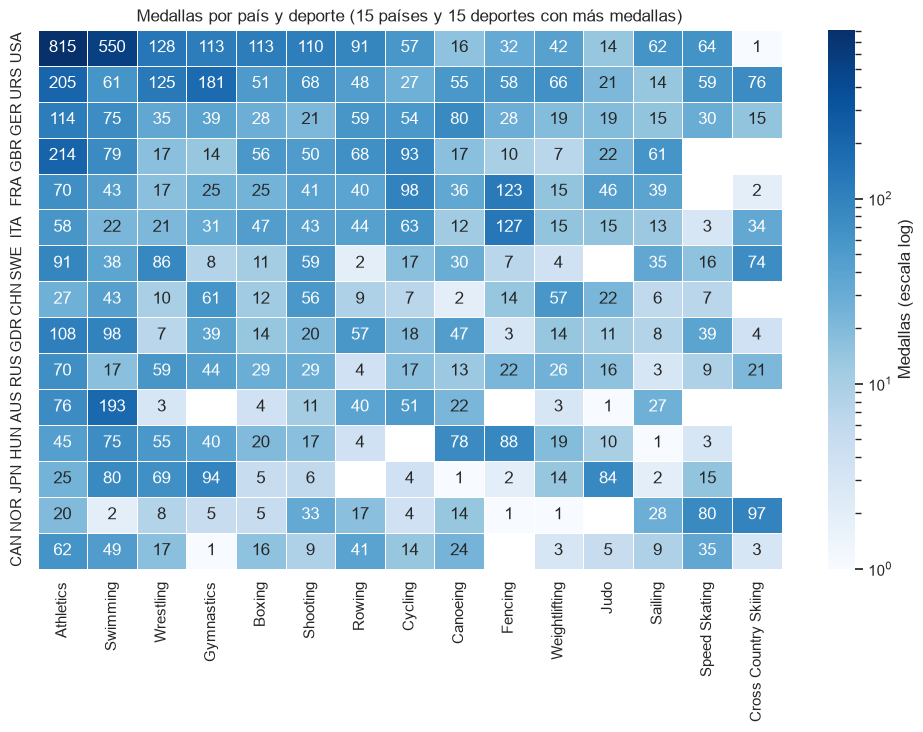

In [37]:
paises = medallas_evento["NOC"].value_counts().head(15).index
deportes = medallas_evento["Sport"].value_counts().head(15).index
mapa = pd.crosstab(medallas_evento["NOC"], medallas_evento["Sport"]).loc[paises, deportes]

plt.figure(figsize=(12, 7))
sns.heatmap(mapa, annot=True, fmt="d", cmap="Blues", norm=LogNorm(vmin=1, vmax=mapa.max().max()),
            mask=mapa == 0, linewidths=0.5, cbar_kws={"label": "Medallas (escala log)"})
plt.grid(False)
plt.title("Medallas por país y deporte (15 países y 15 deportes con más medallas)")
plt.xlabel("")
plt.ylabel("")
plt.show()

Estados Unidos destaca en casi todo, sobre todo en atletismo (815) y natación (550). El resto de países tiene especialidades muy marcadas: Italia y Francia en esgrima, la URSS en gimnasia, Japón en judo, Australia en natación y Noruega en esquí de fondo y patinaje de velocidad. Australia, Hungría o Japón no tienen ninguna medalla en esquí de fondo, y Gran Bretaña ninguna en patinaje de velocidad.

### 3.2 Los diez países con más medallas

**Enunciado.** Obtén el ranquin de los 10 países con mayor número total de medallas (de cualquier tipo) y, para cada uno de esos 10 países, el deporte en el que más medallas ha conseguido.

In [38]:
medallero = pd.crosstab(medallas_evento["NOC"], medallas_evento["Medal"])[["Gold", "Silver", "Bronze"]]
medallero.columns = ["Oro", "Plata", "Bronce"]
medallero["Total"] = medallero.sum(axis=1)
top10_med = medallero.sort_values("Total", ascending=False).head(10)

por_deporte = pd.crosstab(medallas_evento["NOC"], medallas_evento["Sport"]).loc[top10_med.index]
top10_med["Deporte con más medallas"] = por_deporte.idxmax(axis=1)
top10_med["Medallas en ese deporte"] = por_deporte.max(axis=1)

tabla_top10 = top10_med.reset_index(names="País")
tabla_top10.index = range(1, 11)
tabla_top10

,País,Oro,Plata,Bronce,Total,Deporte con más medallas,Medallas en ese deporte
1,USA,1128,897,790,2815,Athletics,815
2,URS,513,413,383,1309,Athletics,205
3,GER,299,334,330,963,Athletics,114
4,GBR,288,319,310,917,Athletics,214
5,FRA,259,279,324,862,Fencing,123
6,ITA,250,214,237,701,Fencing,127
7,SWE,197,215,240,652,Athletics,91
8,CHN,239,185,173,597,Diving,69
9,GDR,227,183,183,593,Athletics,108
10,RUS,171,163,186,520,Athletics,70


Las medallas de equipo cuentan una sola vez, con el criterio explicado al principio del reto, y cada país aparece con su código NOC. Estados Unidos lidera con 2.815 medallas, más del doble que la URSS (1.309). El atletismo es el deporte con más medallas en siete de los diez países, algo esperable porque es el deporte que más medallas reparte. Las excepciones dicen más de cada país: Francia e Italia destacan en esgrima y China en saltos. Alemania aparece en el top 10 con dos códigos, GER y GDR (Alemania del Este), porque entre 1968 y 1988 compitió dividida en dos países; la otra parte, Alemania Occidental, tiene un tercer código, FRG.

### 3.3 Evolución por décadas de los cinco primeros

**Enunciado.** De los 5 países líderes en medallas, calcula la evolución por décadas de su cantidad de medallas (elige y justifica cómo discretizar las décadas). Muestra una serie temporal por décadas y añade una breve conclusión.

Discretizamos por décadas naturales (año // 10 * 10: 1896 cae en 1890, 1906 en 1900, etc.). Así cada edición cae entera en una década y las etiquetas se entienden sin explicación. Como no todas las décadas tienen el mismo número de Juegos, primero contamos cuántas ediciones hubo en cada una.

In [39]:
ediciones = df.drop_duplicates("Games").assign(decada=lambda d: d["Year"] // 10 * 10)
pd.crosstab(ediciones["Season"], ediciones["decada"])

decada,1890,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010
Season,,,,,,,,,,,,,
Summer,1,4,1,3,2,1,2,3,2,3,2,3,2
Winter,0,0,0,2,2,1,2,3,2,3,3,2,2


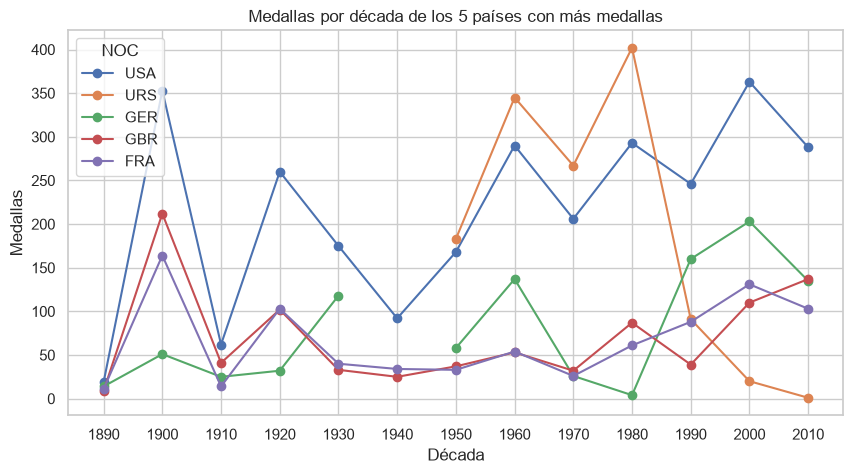

In [40]:
top5_med = top10_med.index[:5]
medallas_evento["decada"] = medallas_evento["Year"] // 10 * 10
por_decada = (medallas_evento[medallas_evento["NOC"].isin(top5_med)]
              .groupby(["decada", "NOC"]).size().unstack()[top5_med])

ax = por_decada.plot(marker="o", figsize=(10, 5))
ax.set_title("Medallas por década de los 5 países con más medallas")
ax.set_xlabel("Década")
ax.set_ylabel("Medallas")
ax.set_xticks(por_decada.index)
plt.show()

La tabla de ediciones explica los picos y valles comunes a todos: la década de 1900 tuvo cuatro Juegos de verano (por los de 1906) y las de 1910 y 1940 solo uno, por las guerras.

**Conclusión.** Estados Unidos es el primero en casi todas las décadas y mantiene una tendencia creciente. Solo la URSS lo superó, desde los años 50 hasta los 80. Las medallas de la URSS después de 1990 no son reales: el dataset asigna un único país a cada atleta, y los que debutaron con la URSS siguen contando para ella aunque compitieran después con otros países. Por el mismo motivo Alemania casi desaparece entre 1968 y 1988, cuando sus atletas compitieron como GDR (Alemania del Este) y FRG (Alemania Occidental). Gran Bretaña es el país que más crece en las últimas décadas y en la de 2010 alcanza a Alemania.

### 3.4 Físico y medallas en remo

**Enunciado.** Elige un deporte y analiza si hay relación entre la altura/peso de los deportistas y probabilidad de medalla en función del país. Compara todos los países para el deporte elegido, muestra una gráfica adecuada e interpreta los resultados (en 5–8 líneas).

Elegimos el **remo** porque es un deporte en el que la palanca de los brazos y la fuerza mueven el bote, así que es razonable esperar que la talla influya.

Como probabilidad de medalla de cada país usamos el porcentaje de participaciones de sus remeros (un remero en una prueba) que terminaron en medalla. Por ejemplo, si los remeros de un país suman 100 participaciones y 20 medallas, su porcentaje es del 20 %. Lo calculamos con todas las participaciones del país, y la altura y el peso medios con los remeros que tienen ese dato.

Separamos hombres y mujeres, porque si no un país con más remeras tendría una altura media más baja solo por la composición del equipo. Comparamos todos los países con al menos 15 remeros: con menos, un país con dos participaciones y una medalla saldría con un 50 % que no significa nada.

In [41]:
remo = df[df["Sport"] == "Rowing"]
por_pais = (remo.groupby(["Sex", "NOC"])
            .agg(remeros=("ID", "nunique"), altura=("Height", "mean"), peso=("Weight", "mean"),
                 medalla=("medalla", "mean"))
            .reset_index())
por_pais["medalla"] *= 100
por_pais = por_pais.rename(columns={"medalla": "% con medalla"})
print("Países con remeros:", por_pais.groupby("Sex").size().to_dict())
por_pais = por_pais[por_pais["remeros"] >= 15].dropna(subset=["altura", "peso"])
print("Países con al menos 15 remeros:", por_pais.groupby("Sex").size().to_dict())

Países con remeros: {'F': 66, 'M': 93}
Países con al menos 15 remeros: {'F': 22, 'M': 49}


Para ver si hay relación, dividimos los países de cada sexo en dos grupos según si la altura media de sus remeros está por encima o por debajo de la mediana (el valor que deja a la mitad de los países a cada lado), y comparamos el porcentaje de medallas medio de cada grupo. Hacemos lo mismo con el peso.

In [42]:
comparacion_remo = {}
for var in ["altura", "peso"]:
    mediana = por_pais.groupby("Sex")[var].transform("median")
    grupo = np.where(por_pais[var] > mediana, "por encima de la mediana", "por debajo de la mediana")
    comparacion_remo[f"% con medalla según {var}"] = por_pais.groupby(["Sex", grupo])["% con medalla"].mean()
pd.DataFrame(comparacion_remo).rename_axis([None, None]).round(1)

% con medalla según altura  \
F por debajo de la mediana                        24.4   
  por encima de la mediana                        32.4   
M por debajo de la mediana                        13.2   
  por encima de la mediana                        24.3   

                            % con medalla según peso  
F por debajo de la mediana                      14.6  
  por encima de la mediana                      42.3  
M por debajo de la mediana                      12.0  
  por encima de la mediana                      25.6

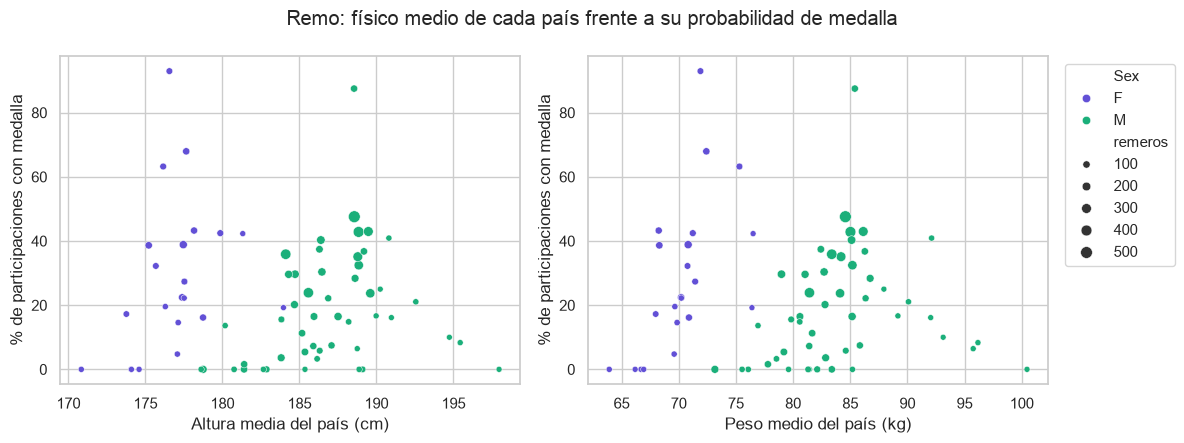

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, var in zip(axes, ["altura", "peso"]):
    sns.scatterplot(data=por_pais, x=var, y="% con medalla", hue="Sex", size="remeros",
                    palette={"F": "#6250d6", "M": "#1baf7a"}, ax=ax, legend=(var == "peso"))
    ax.set_ylabel("% de participaciones con medalla")
axes[0].set_xlabel("Altura media del país (cm)")
axes[1].set_xlabel("Peso medio del país (kg)")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Remo: físico medio de cada país frente a su probabilidad de medalla")
plt.tight_layout()
plt.show()

In [44]:
por_pais.sort_values("% con medalla", ascending=False).head(5).round(1)

,Sex,NOC,remeros,altura,peso,% con medalla
24,F,GDR,62,176.6,71.9,92.9
98,M,GDR,97,188.5,85.4,87.5
47,F,ROU,98,177.6,72.4,67.9
61,F,URS,68,176.2,75.3,63.2
153,M,USA,506,188.6,84.6,47.6


**Por qué un diagrama de dispersión.** Cada punto es un país, con el físico medio de sus remeros en el eje horizontal y su porcentaje de medallas en el vertical. Así se comparan todos los países a la vez y se ve si los puntos tienden a subir hacia la derecha. El tamaño del punto indica cuántos remeros tiene cada país.

**Interpretación.** Sí hay relación: los países con remeros más altos y pesados ganan medalla con más frecuencia. En hombres, los países por encima de la altura mediana ganan medalla en el 24,3 % de sus participaciones, frente al 13,2 % de los que están por debajo; en mujeres, 32,4 % frente a 24,4 %. Con el peso la diferencia es todavía mayor, sobre todo en mujeres (42,3 % frente a 14,6 %). Aun así, el físico no lo explica todo. En el gráfico hay países con remeros altos y pocas medallas, y la RDA queda muy por encima de todos (87,5 % en hombres y 92,9 % en mujeres) con un físico parecido al de Estados Unidos. La talla parece necesaria para competir arriba, pero la preparación y la tradición de cada país marcan la diferencia.

Hay que tener en cuenta dos limitaciones. Falta la altura o el peso en el 26 % de las participaciones de remo. Además, en algunos botes va un timonel, que no rema sino que dirige el bote y suele ser bajo y ligero para que el bote pese menos. Como gana la misma medalla que sus compañeros, baja la altura y el peso medios de su país, aunque no tenga que ver con la fuerza del equipo.

## B) Función de ranking de países

**Qué hace.** ranking_paises_medallas(df_medallas, k) devuelve los k países con más medallas como una lista de diccionarios, con el formato del enunciado.

**Decisiones.** Las medallas se cuentan por prueba, con el mismo criterio que en el resto del reto. El país no está en la tabla de medallas sino en la de atletas, así que la función recibe df_atletas como tercer parámetro para hacer el cruce. Por defecto es la tabla de atletas ya limpia, de modo que se puede llamar como en el enunciado, ranking_paises_medallas(df_medallas, k). Las cinco reglas de desempate se aplican en un solo paso, ordenando por cinco columnas: oros, platas y bronces de mayor a menor, y primer año con medalla y código de país de menor a mayor.

In [45]:
def ranking_paises_medallas(df_medallas, k, df_atletas=df_atletas):
    if "NOC" not in df_medallas.columns:
        df_medallas = df_medallas.merge(df_atletas[["ID", "NOC"]], on="ID")
    med = df_medallas[df_medallas["Medal"].notna()].drop_duplicates(["Games", "Event", "NOC", "Medal"])

    tabla = pd.crosstab(med["NOC"], med["Medal"]).reindex(columns=["Gold", "Silver", "Bronze"], fill_value=0)
    tabla["primer_anio"] = med.groupby("NOC")["Year"].min()
    tabla = tabla.reset_index().sort_values(["Gold", "Silver", "Bronze", "primer_anio", "NOC"],
                                            ascending=[False, False, False, True, True]).head(k)
    return [{"orden": i, "país": f["NOC"], "oro": f["Gold"], "plata": f["Silver"],
             "bronce": f["Bronze"], "primer_año": f["primer_anio"]}
            for i, f in enumerate(tabla.to_dict("records"), start=1)]

In [46]:
ranking = ranking_paises_medallas(df_medallas, 10)
print("Primer elemento de la lista:", ranking[0])
pd.DataFrame(ranking)

Primer elemento de la lista: {'orden': 1, 'país': 'USA', 'oro': 1128, 'plata': 897, 'bronce': 790, 'primer_año': 1896}


,orden,país,oro,plata,bronce,primer_año
0,1,USA,1128,897,790,1896
1,2,URS,513,413,383,1952
2,3,GER,299,334,330,1896
3,4,GBR,288,319,310,1896
4,5,FRA,259,279,324,1896
5,6,ITA,250,214,237,1900
6,7,CHN,239,185,173,1984
7,8,GDR,227,183,183,1968
8,9,SWE,197,215,240,1900
9,10,HUN,178,155,175,1896


**Caso de prueba.** Con datos inventados, cada pareja de países solo se puede separar con una regla distinta.

In [47]:
prueba = pd.DataFrame({
    "NOC":   ["AAA", "BBB", "BBB", "CCC", "CCC", "DDD", "EEE"],
    "Medal": ["Gold", "Silver", "Bronze", "Silver", "Bronze", "Bronze", "Bronze"],
    "Year":  [2000, 2000, 2000, 1990, 1990, 2000, 2000]})
prueba["Games"] = prueba["Year"].astype(str) + " Summer"
prueba["Event"] = [f"prueba {i}" for i in range(len(prueba))]

orden = [f["país"] for f in ranking_paises_medallas(prueba, 5)]
# AAA gana por oros; CCC va antes que BBB por tener medalla antes; DDD antes que EEE por orden alfabético
assert orden == ["AAA", "CCC", "BBB", "DDD", "EEE"], orden
print("Pruebas superadas:", orden)

Pruebas superadas: ['AAA', 'CCC', 'BBB', 'DDD', 'EEE']


Al ordenar por oros en lugar de por total, el top 10 cambia respecto al de 3.2: China adelanta a Suecia, que tiene más medallas pero menos oros, y Hungría entra en lugar de Rusia.

<a id='reto4'></a>
# Reto 4. Participación de las mujeres

**Objetivo.** Medir cómo ha evolucionado la presencia de mujeres en los Juegos y si hoy está equilibrada entre países, entre deportes y en el número de pruebas. Es un objetivo verificable con los datos, porque cada participación tiene sexo, año, temporada, país, deporte y prueba. Lo elegimos porque en 2.3 vimos que solo una de cada cuatro participantes es mujer, pero es una media de 120 años que no dice si la situación ha cambiado.

**Tareas.**
1. Evolución del porcentaje de mujeres en cada edición, separando verano e invierno.
2. Países con más y menos presencia de mujeres en los últimos Juegos de verano (Río 2016).
3. Comparación entre el porcentaje de pruebas femeninas y el porcentaje de mujeres participantes.
4. Porcentaje de mujeres en cada deporte en Río 2016.

## A) Tareas de análisis

### 4.1 Evolución del porcentaje de mujeres

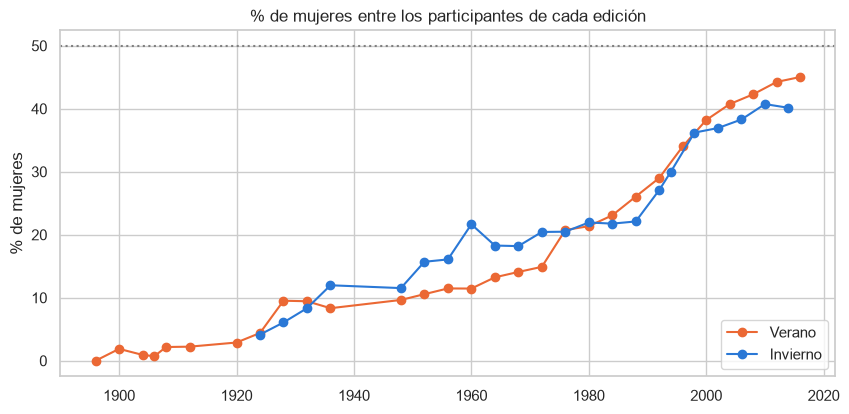

In [48]:
pct_mujeres = (participaciones.groupby(["Year", "Season"])["Sex"]
               .apply(lambda s: 100 * (s == "F").mean()).unstack())

fig, ax = plt.subplots(figsize=(10, 4.5))
for temporada in ["Summer", "Winter"]:
    serie = pct_mujeres[temporada].dropna()
    ax.plot(serie.index, serie.values, marker="o", color=COLOR_TEMP[temporada])
ax.axhline(50, color="grey", linestyle=":")
ax.set_title("% de mujeres entre los participantes de cada edición")
ax.set_ylabel("% de mujeres")
ax.legend(["Verano", "Invierno"])
plt.show()

In [49]:
pct_mujeres.loc[[1900, 1936, 1964, 1988, 2014, 2016]].round(1)

Season,Summer,Winter
Year,,
1900,1.9,NaN
1936,8.3,12.0
1964,13.2,18.3
1988,26.1,22.1
2014,NaN,40.1
2016,45.0,NaN


Las mujeres pasaron de ser el 2 % de los participantes de verano en 1900 al 45 % en Río 2016. El crecimiento fue lento hasta los años 70 y se aceleró a partir de los 80. En invierno la tendencia es la misma y llegó al 40 % en Sochi 2014. En ninguna temporada se ha alcanzado todavía la paridad.

### 4.2 Diferencias entre países en Río 2016

Una delegación pequeña da porcentajes poco fiables: con 5 atletas, cada persona cambia el porcentaje en 20 puntos, y un país con una sola atleta saldría con un 100 %. Por eso tomamos los países que llevaron al menos 50 atletas, en los que cada persona cambia el porcentaje en 2 puntos como mucho. Un umbral más alto, como 100 atletas, dejaría solo 32 de los 213 países.

Países en Río 2016: 213
Países con al menos 50 atletas: 58
Mediana del % de mujeres en esos países: 44.2
Países por debajo del 40 %: 22


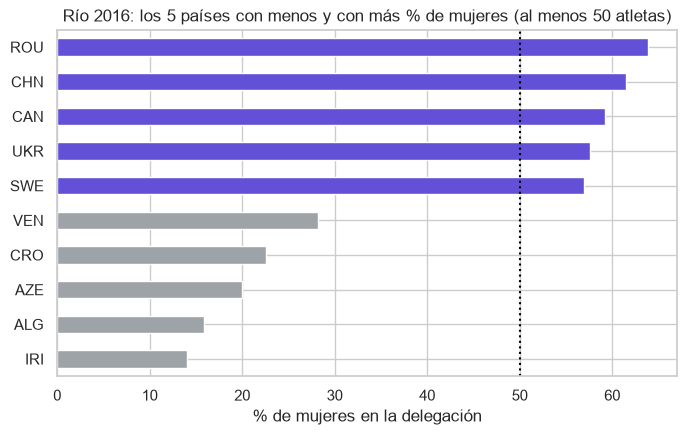

In [50]:
rio = participaciones[participaciones["Games"] == "2016 Summer"]
por_pais_rio = rio.groupby("NOC").agg(atletas=("ID", "size"), mujeres=("Sex", lambda s: 100 * (s == "F").mean()))
por_pais_rio = por_pais_rio.rename(columns={"mujeres": "% mujeres"}).rename_axis(None)
print("Países en Río 2016:", len(por_pais_rio))
por_pais_rio = por_pais_rio[por_pais_rio["atletas"] >= 50].sort_values("% mujeres")
print("Países con al menos 50 atletas:", len(por_pais_rio))
print("Mediana del % de mujeres en esos países:", round(por_pais_rio["% mujeres"].median(), 1))
print("Países por debajo del 40 %:", (por_pais_rio["% mujeres"] < 40).sum())

extremos_rio = pd.concat([por_pais_rio.head(5), por_pais_rio.tail(5)])
ax = extremos_rio["% mujeres"].plot(kind="barh", figsize=(8, 4.5), color=["#9ea3a8"] * 5 + ["#6250d6"] * 5)
ax.axvline(50, color="black", linestyle=":")
ax.set_title("Río 2016: los 5 países con menos y con más % de mujeres (al menos 50 atletas)")
ax.set_xlabel("% de mujeres en la delegación")
plt.show()

In [51]:
extremos_rio.round(1)

,atletas,% mujeres
IRI,64,14.1
ALG,63,15.9
AZE,50,20.0
CRO,84,22.6
VEN,85,28.2
SWE,151,57.0
UKR,212,57.5
CAN,309,59.2
CHN,392,61.5
ROU,94,63.8


Entre los 58 países con al menos 50 atletas, la mediana es del 44,2 % de mujeres, pero las diferencias son grandes. Rumanía (63,8 %), China (61,5 %) y Canadá (59,2 %) llevaron más mujeres que hombres. En el otro extremo, Irán (14,1 %), Argelia (15,9 %) y Azerbaiyán (20,0 %) llevaron una mujer o menos por cada cinco atletas. En total, 22 de los 58 países quedaron por debajo del 40 %.

### 4.3 Pruebas para mujeres

Hombres y mujeres compiten por separado, así que las medallas que pueden ganar las mujeres dependen de cuántas pruebas femeninas hay en el programa, no de cómo rinden frente a los hombres. Por eso no comparamos medallas, sino el porcentaje de pruebas femeninas con el porcentaje de mujeres entre los participantes, en cada edición de verano.

Cada prueba se clasifica por su nombre: es femenina si contiene "Women's", masculina si contiene "Men's" y mixta en el resto de casos, como la hípica, donde compiten juntos. El porcentaje se calcula sobre las pruebas masculinas y femeninas.

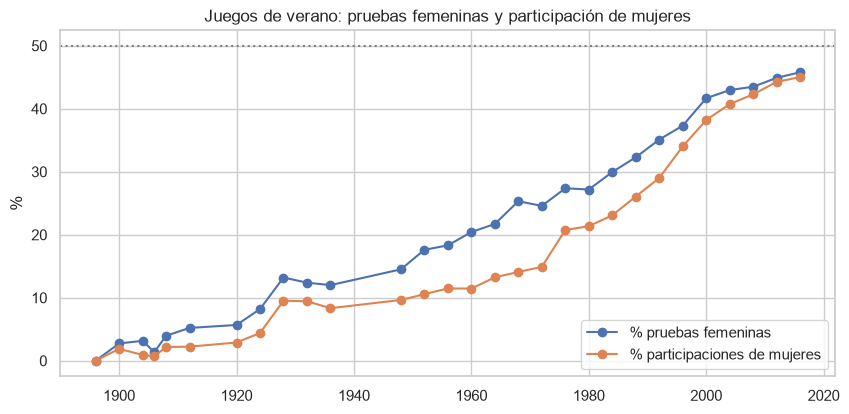

In [52]:
pruebas = df[df["Season"] == "Summer"].drop_duplicates(["Games", "Event"]).copy()
pruebas["tipo"] = "Mixta"
pruebas.loc[pruebas["Event"].str.contains("Men's"), "tipo"] = "Hombres"
pruebas.loc[pruebas["Event"].str.contains("Women's"), "tipo"] = "Mujeres"

tipos = pd.crosstab(pruebas["Year"], pruebas["tipo"]).rename_axis(index=None, columns=None)
evolucion = pd.DataFrame({
    "% pruebas femeninas": 100 * tipos["Mujeres"] / (tipos["Mujeres"] + tipos["Hombres"]),
    "% participaciones de mujeres": pct_mujeres["Summer"].dropna(),
})
ax = evolucion.plot(marker="o", figsize=(10, 4.5))
ax.axhline(50, color="grey", linestyle=":")
ax.set_title("Juegos de verano: pruebas femeninas y participación de mujeres")
ax.set_ylabel("%")
plt.show()

In [53]:
print("Ediciones en las que el % de pruebas femeninas supera al de participaciones:",
      (evolucion["% pruebas femeninas"] > evolucion["% participaciones de mujeres"]).sum(), "de", len(evolucion))
evolucion.join(tipos).loc[[1900, 1924, 1960, 1976, 2000, 2016]].round(1)

Ediciones en las que el % de pruebas femeninas supera al de participaciones: 28 de 29


,% pruebas femeninas,% participaciones de mujeres,Hombres,Mixta,Mujeres
1900,2.7,1.9,71,17,2
1924,8.2,4.4,112,4,10
1960,20.4,11.5,113,8,29
1976,27.4,20.7,130,19,49
2000,41.7,38.2,168,12,120
2016,45.8,45.0,161,9,136


Las dos líneas crecen a la par. En 1960 solo el 20,4 % de las pruebas eran femeninas, y en 2016 ya eran el 45,8 % (136 pruebas femeninas frente a 161 masculinas), casi el mismo porcentaje que el de mujeres entre los participantes (45,0 %). La presencia de mujeres ha aumentado a medida que se han creado pruebas para ellas.

La línea de pruebas va por encima de la de participación en todas las ediciones menos en 1896, cuando no compitió ninguna mujer. Eso significa que, durante décadas, las pruebas femeninas tuvieron menos participantes que las masculinas; en 2016 esa diferencia prácticamente ha desaparecido. Como en cada prueba se reparte el mismo número de medallas, la parte de las medallas que ganan las mujeres depende del número de pruebas femeninas y no sirve para medir su rendimiento frente a los hombres.

### 4.4 Diferencias entre deportes en Río 2016

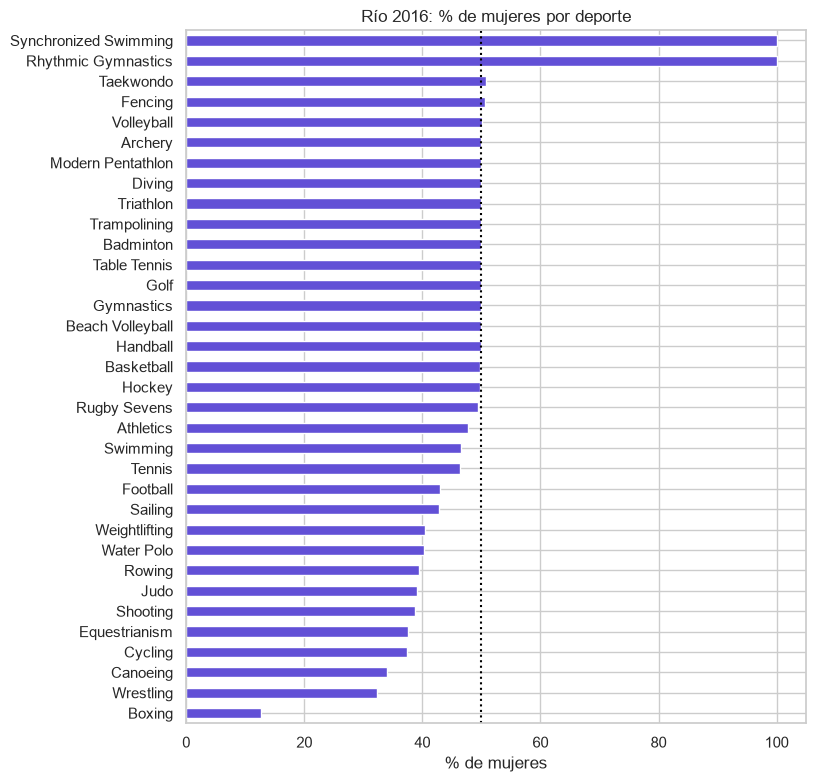

Deportes por debajo del 45 %: ['Boxing', 'Wrestling', 'Canoeing', 'Cycling', 'Equestrianism', 'Shooting', 'Judo', 'Rowing', 'Water Polo', 'Weightlifting', 'Sailing', 'Football']


In [54]:
por_deporte_rio = rio.groupby("Sport")["Sex"].apply(lambda s: 100 * (s == "F").mean()).sort_values()
ax = por_deporte_rio.plot(kind="barh", figsize=(8, 9), color="#6250d6")
ax.axvline(50, color="black", linestyle=":")
ax.set_title("Río 2016: % de mujeres por deporte")
ax.set_xlabel("% de mujeres")
ax.set_ylabel("")
plt.show()
print("Deportes por debajo del 45 %:", list(por_deporte_rio[por_deporte_rio < 45].index))

Para entender por qué algunos deportes tienen menos mujeres, contamos cuántas pruebas había para cada sexo en esos deportes en Río 2016.

In [55]:
pruebas_rio = pruebas[pruebas["Year"] == 2016]
desequilibrados = por_deporte_rio[por_deporte_rio < 45].index
pd.crosstab(pruebas_rio["Sport"], pruebas_rio["tipo"]).loc[desequilibrados].rename_axis(index=None, columns=None)

,Hombres,Mixta,Mujeres
Boxing,10,0,3
Wrestling,12,0,6
Canoeing,11,0,5
Cycling,9,0,9
Equestrianism,0,6,0
Shooting,9,0,6
Judo,7,0,7
Rowing,8,0,6
Water Polo,1,0,1
Weightlifting,8,0,7


La mayoría de deportes está cerca del 50 %, pero doce quedan por debajo del 45 %. La tabla muestra que, dentro de un deporte, no compiten necesariamente los mismos hombres que mujeres, y hay dos motivos. En algunos deportes hay menos pruebas femeninas: en boxeo había 10 pruebas masculinas y 3 femeninas, en lucha 12 y 6, en piragüismo 11 y 5, y en tiro 9 y 6. En otros el número de pruebas es el mismo, pero las femeninas tienen menos plazas: en fútbol y waterpolo hay una prueba por sexo, pero el torneo femenino tiene menos equipos, y en ciclismo y judo hay las mismas pruebas pero menos participantes mujeres. La hípica es un caso aparte, porque sus pruebas son mixtas y hombres y mujeres compiten juntos. En el otro extremo, la gimnasia rítmica y la natación sincronizada siguen siendo exclusivamente femeninas.

**Por qué estos gráficos.** Para la evolución en el tiempo (4.1 y 4.3) usamos líneas, porque muestran la tendencia y permiten comparar dos series en el mismo eje. Para comparar países y deportes (4.2 y 4.4) usamos barras horizontales ordenadas, que se leen mejor cuando las etiquetas son nombres. En todos marcamos el 50 % para ver de un vistazo la distancia a la paridad.

## B) Función del año en que un país alcanza un porcentaje de mujeres

**Perfil.** anio_umbral_mujeres(noc, df, umbral=30, temporada="Summer")

**Qué hace.** Devuelve el primer año en que la delegación de un país alcanzó un porcentaje de mujeres dado, en verano o en invierno. Sirve para comparar cuándo llegó cada país a un nivel de presencia femenina, algo que las tareas anteriores no muestran.

**Salida.** Un año (int), o None si el país no existe en los datos o nunca llegó al umbral.

**Casos de prueba.** Un país que no existe, un umbral imposible (101 %), un umbral de 0 (debe devolver el primer año del país) y la coherencia entre umbrales (un umbral más alto no puede alcanzarse antes que uno más bajo).

In [56]:
def anio_umbral_mujeres(noc, df, umbral=30, temporada="Summer"):
    datos = df[(df["NOC"] == noc) & (df["Season"] == temporada)].drop_duplicates(["ID", "Games"])
    if datos.empty:
        return None
    pct = datos.groupby("Year")["Sex"].apply(lambda s: 100 * (s == "F").mean())
    alcanzado = pct[pct >= umbral]
    return int(alcanzado.index.min()) if not alcanzado.empty else None

In [57]:
primer_anio_usa = participaciones.query("NOC == 'USA' and Season == 'Summer'")["Year"].min()
assert anio_umbral_mujeres("XXX", df) is None
assert anio_umbral_mujeres("USA", df, umbral=101) is None
assert anio_umbral_mujeres("USA", df, umbral=0) == primer_anio_usa
assert anio_umbral_mujeres("USA", df, 20) <= anio_umbral_mujeres("USA", df, 40)
print("Pruebas superadas")

Pruebas superadas


Aplicamos la función a los 10 países con más atletas para tres umbrales.

In [58]:
paises10 = df_atletas["NOC"].value_counts().head(10).index
pd.DataFrame({f"año ≥ {u} %": [anio_umbral_mujeres(p, df, u) for p in paises10] for u in [20, 30, 40]},
             index=paises10).rename_axis(None)

,año ≥ 20 %,año ≥ 30 %,año ≥ 40 %
USA,1964,1984,1996
GBR,1964,1980,2000
FRA,1984,1996,2012
ITA,1980,2000,2012
CAN,1968,1976,1996
GER,1992,1992,1996
JPN,1976,1992,1996
AUS,1928,1932,2000
SWE,1972,1996,2004
URS,1968,1976,1992


In [59]:
aus_1928 = participaciones.query("NOC == 'AUS' and Games == '1928 Summer'")
print("Australia 1928:", len(aus_1928), "atletas, de ellos", (aus_1928["Sex"] == "F").sum(), "mujeres")

Australia 1928: 18 atletas, de ellos 4 mujeres


La mayoría de estos países superó el 30 % de mujeres entre 1976 y 2000 y el 40 % entre 1992 y 2012. Francia e Italia fueron las últimas en llegar al 40 % (2012). Hay tres resultados que no deben leerse literalmente:
- Australia aparece con un 20 % ya en 1928, pero solo llevó 18 atletas, 4 de ellos mujeres. Con una delegación tan pequeña, cuatro personas bastan para un porcentaje alto.
- Alemania no alcanza el 20 % hasta 1992. Entre 1968 y 1988 compitió dividida en dos países, con los códigos GDR (Alemania del Este) y FRG (Alemania Occidental), así que las atletas alemanas de esos años no cuentan en GER.
- La URSS aparece en 1992, cuando ya no existía. En el dataset cada atleta tiene un único país, y quienes debutaron con la URSS siguen contando para ella aunque en 1992 compitieran con otro equipo.

## Conclusión

La presencia de mujeres en los Juegos ha crecido de forma continua, del 2 % de los participantes de verano en 1900 al 45 % en Río 2016, con una aceleración clara desde los años 80. En invierno la tendencia es la misma. Ese crecimiento ha ido unido a la creación de pruebas femeninas: en 2016 el 45,8 % de las pruebas eran femeninas, casi el mismo porcentaje que el de mujeres participantes. La paridad todavía no es completa. Algunos países, como Irán o Argelia, llevan una mujer o menos por cada cinco atletas, y deportes como el boxeo o la lucha siguen muy desequilibrados porque tienen menos pruebas femeninas que masculinas.

**Limitaciones del dataset que afectan a esta interpretación.**
- Cada atleta tiene un único país. Por eso la URSS aparece en ediciones posteriores a su desaparición, y Alemania figura con tres códigos según la época (GER, GDR y FRG), lo que altera los años que devuelve la función para esos países.
- En las primeras ediciones las delegaciones eran muy pequeñas, y unas pocas atletas bastaban para alcanzar un porcentaje alto, como le ocurre a Australia en 1928. Los porcentajes de esos años son poco fiables.
- Las pruebas se clasifican por su nombre. Las mixtas, en las que hombres y mujeres compiten juntos, no cuentan ni como masculinas ni como femeninas. En cambio, el porcentaje de participantes sí incluye a quienes compitieron en ellas, en su mayoría hombres, lo que agranda un poco la distancia entre las dos líneas de 4.3.